# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [4]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


필수 패키지가 이미 준비되어 있습니다.
Python: 3.11.18


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [5]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: /home/minheekim/study/ai-mini-projects/ai-miniproject02/nlp_bert_mini
PyTorch: 2.15.0+cu132 | Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [6]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


저장된 프로젝트 데이터셋을 재사용합니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


/home/minheekim/study/ai-mini-projects/ai-miniproject02/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


텍스트 길이 분석
count    200.00000
mean     499.66000
std        0.53463
min      498.00000
25%      499.00000
50%      500.00000
75%      500.00000
max      500.00000
Name: char_length, dtype: float64

질문 길이 분석
count    60.000000
mean     29.216667
std       8.427340
min      13.000000
25%      23.750000
50%      28.000000
75%      36.000000
max      54.000000
Name: char_length, dtype: float64



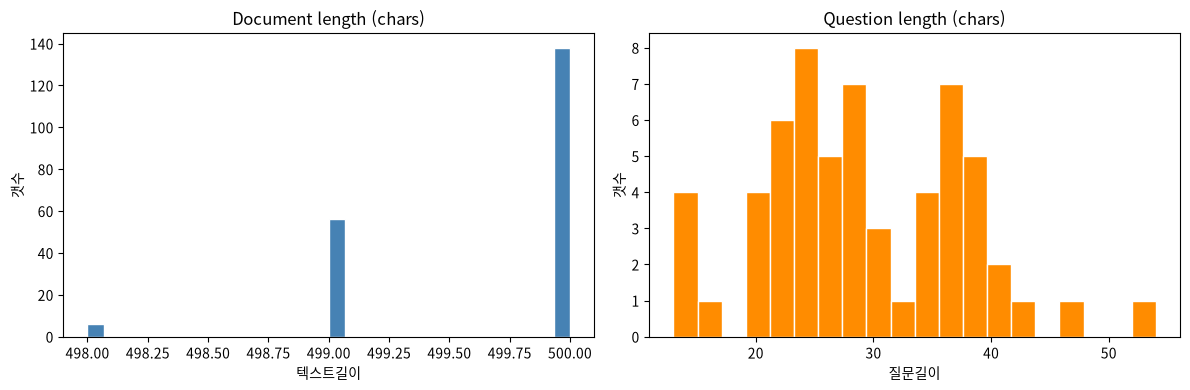

In [ ]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()
corpus_stats['char_length'] = corpus_stats['text'].str.len()
valid_stats['char_length'] = valid_stats['question'].str.len()
print('문서 길이 분석')
print(corpus_stats['char_length'].describe())
print('')
print('질문 길이 분석')
print(valid_stats['char_length'].describe())
print('')

plt.rcParams['font.family'] = 'Noto Sans CJK KR'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(12, 4))   # 1행 2열: 그래프 2개를 나란히



axes[0].hist(corpus_stats['char_length'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Document length (chars)')
axes[0].set_xlabel('문서길이')
axes[0].set_ylabel('갯수')

axes[1].hist(valid_stats['char_length'], bins=20, color='darkorange', edgecolor='white')
axes[1].set_title('Question length (chars)')
axes[1].set_xlabel('질문길이')
axes[1].set_ylabel('갯수')

fig.tight_layout()
fig.savefig(FIGURES / 'cp01_length_hist.png', dpi=150, bbox_inches='tight')
plt.show()


# TODO 1-1. corpus_stats['char_length']에 문서 text의 글자 수를 계산해 넣으세요.
# TODO 1-2. valid_stats['char_length']에 질문 question의 글자 수를 계산해 넣으세요.
# TODO 1-3. describe()로 문서·질문 길이 통계를 출력하세요.
# TODO 1-4. 두 길이 분포를 histogram으로 시각화하고 FIGURES에 저장하세요.
#             matplotlib의 plt.subplots(), ax.hist(), fig.savefig()를 사용합니다.
# raise NotImplementedError('CP-01 길이 분석·그래프 TODO를 완성하세요.')


**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [8]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징: 질문길이는 10~40사이에 분포되어있고 문서길이는 498,499,500 정도로 비슷하게 구성되어있습니다.
- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징: 평균이 0.474 이고 질문의 50%의 겹침비율이 0.462이고 75%의 겹침비율이 0.601 인것으로 보아 절반 가까이 (50%~75% 사이) 되는 질문이 문서와 겹치는것으로 보입니다.
- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유: 질문과 겹치는 단어가 문서 본문에 있는 질문이고, TF-IDF가 전체 문서에서 해당 단어의 포함되는것을 찾는것이기때문입니다.
- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유: 질문과 문서가 내용은 맞지만 포함되는 겹치는 단어가 없을때이고, TF-IDF 는 맥락은 보지않고 무조건 단어의 겹침여부로 판단하기 때문입니다.

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [9]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=30000)
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'])

# TODO 2-1. analyzer='char', ngram_range=(2, 3), max_features=30000인 TfidfVectorizer를
#           tfidf_vectorizer라는 이름으로 만드세요.
# TODO 2-2. Corpus의 text로 fit_transform()하여 tfidf_docs를 만드세요.


def top_k_results(scores, frame, k=5):
    """점수가 높은 문서 k개를 반환합니다. 키: rank, doc_id, score, text"""
    scores = np.asarray(scores, dtype=np.float64).ravel()
    assert len(scores) == len(frame)
    k = min(max(1, int(k)), len(frame))
    top_k_idx = np.argsort(-scores)[:k]

    results = []
    for rank, idx in enumerate(top_k_idx, start=1):
        row = frame.iloc[idx]
        results.append({
            'rank': rank,
            'doc_id': row['doc_id'],
            'score': float(scores[idx]),
            'text': row['text']
        })
    return results

    # TODO 2-3. np.argsort(-scores)로 점수 내림차순 상위 k개 인덱스를 고르세요.
    # TODO 2-4. 위 인덱스로 rank, doc_id, score, text 키를 이 순서대로 가진 딕셔너리 리스트를 반환하세요.
    #           rank는 1부터 시작합니다. 검증 셀이 키의 순서까지 확인합니다.
    # raise NotImplementedError('CP-02 Top-k 정렬을 구현하세요.')


def search_tfidf(query, k=5):
    query_vec = tfidf_vectorizer.transform([query])
    scores = cosine_similarity(query_vec, tfidf_docs)[0]
    return top_k_results(scores, corpus_df, k)
    
    # TODO 2-5. tfidf_vectorizer.transform()으로 질문을 벡터로 만드세요.
    # TODO 2-6. cosine_similarity()로 전체 문서와의 점수를 계산하세요.
    # TODO 2-7. top_k_results()를 호출해 검색 결과를 반환하세요.
    # aise NotImplementedError('CP-02 TF-IDF 검색 함수를 구현하세요.')

# TODO 2-8. Validation 질문 하나로 상위 3개 문서를 출력해 보세요.

query = valid_df.iloc[3]['question']
print('query:', query)
search_tfidf(query, 3)


query: 그리스가 제출한 구제금융안의 재정지출 감축 규모는?


[{'rank': 1,
  'doc_id': 'D180',
  'score': 0.28707619993400435,
  'text': '라고 풀이했다.AP통신은 그리스가 연금 삭감과 부가가치세율, 법인세율 인상 등을 주요 내용으로 하는 구제금융안을 제출 마감일인 9일(현지시간) 채권단에 전달했다고 10일 보도했다. 그리스는 향후 2년간의 재정지출 감축 규모로 지난달 채권단과 공감대를 이뤘던 79억유로(약 9조9190억원)보다 오히려 65% 가까이 증가한 130억유로를 제시했다. 2022년까지 은퇴연령을 현재 60세(여성) 또는 65세(남성)에서 67세로 연장하는 등의 연금개혁을 통해 올해 최대 10억유로, 내년에는 20억유로 정도의 지출을 줄이겠다고 밝혔다. 블룸버그통신은 “그리스 정부가 제출한 긴축 규모는 그리스 국민이 투표를 통해 거부했던 채권단의 개혁안과 같은 수준”이라고 평가했다.알렉시스 치프라스 그리스 총리는 지난달 말 채권단을 ‘약탈자’로 표현하며 요구 사항을 절대 들어주지 못하겠다고 버텼지만 불과 열흘 만에 고개를 숙였다. 외신들은 ECB의 긴급유동성지원(ELA) 없이는 시중은행들이 하루도 견딜 수 없을'},
 {'rank': 2,
  'doc_id': 'D145',
  'score': 0.05095251522350453,
  'text': '2008년 9월15일 미국 투자은행(IB) 리먼브러더스의 파산으로 시작된 글로벌 금융위기가 발생한 지 5년이 지났다. 위기의 진원지인 미국의 은행 등 금융회사들은 인력 감축과 새로운 수익원 발굴로 다시 살아났다는 평가를 받고 있다.자산 기준 미국 최대 은행인 JP모건체이스의 순이익은 지난 2분기 65억달러로 전년 동기(50억달러)보다 30% 늘었다. 1위 IB인 골드만삭스도 2분기에 19억3000만달러의 순이익을 기록했다. 주당 순이익은 3.70달러로 1년 전(1.78달러)에 비해 두 배 이상 증가했다. 모건스탠리도 작년 같은 기간보다 66% 증가한 9억8000만달러의 순이익을 올렸다.금융위기로 고사 위기에 

**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [10]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [11]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

BASE_MODEL = 'klue/bert-base'
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)
bert_model = bert_model.to(DEVICE).eval()
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)


BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [12]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
sample_questions = valid_df['question'].head(2).astype(str).tolist()
# TODO 3-1. tokenizer()로 질문 두 개를 padding/truncation하여 return_tensors='pt'로 만들고
#           inputs라는 이름으로 저장하세요.
inputs = tokenizer(sample_questions, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
print('inputs:', inputs)

# TODO 3-2. 입력 Tensor를 DEVICE로 옮기세요.
inputs.to(DEVICE)

# TODO 3-3. torch.inference_mode() 안에서 bert_model(**inputs)를 실행하세요.
with torch.inference_mode():
    outputs = bert_model(**inputs)

# TODO 3-4. 출력의 last_hidden_state는 last_hidden, 입력의 attention_mask는 mask라는 이름으로 저장하고
#           두 Tensor의 Shape와 문장별 유효 토큰 수를 출력하세요.
last_hidden = outputs['last_hidden_state']
mask = inputs['attention_mask']
print('last_hidden:', last_hidden.shape)
print('mask:', mask.shape)

# [주의] 다음 CP-04 셀이 last_hidden과 mask라는 이름을 그대로 사용합니다.
# raise NotImplementedError('CP-03 BERT Encoder의 입력·출력 Shape를 확인하세요.')


inputs: {'input_ids': tensor([[    2,  4786,  4413,  1537,  4353, 27135,  4316,  2138,   706,  2359,
          2414,  9268,  2073,    35,     3,     0,     0,     0,     0],
        [    2,  1269,  5285,  2079,  7847,  9366,  2069,  4025,  2085,  1295,
          1513,  2259, 14645,  2079,  9263,  4347,  2073,    35,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}
last_hidden: torch.Size([2, 19, 768])
mask: torch.Size([2, 19])


**[기록] 결과 해석 — CP-03**

- `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: 질문 수, 토큰의 갯수, 토큰당 벡터 차원의 수
- `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: 평균계산에서 포함시키면 패딩같은 벡터가 계산에 포함되어서 의미없는 벡터가 되고 이걸로 평균을 구하면 벡터의 방향이 실제 내용과 다르게 됩니다.

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.


---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [13]:
# [학생 구현] CP-04 — Masked Mean Pooling

def mean_pooling(last_hidden_state, attention_mask):
    """(B,T,H)+(B,T) → (B,H), 패딩 제외 토큰 평균."""
    # TODO 4-1. 패딩 위치의 벡터가 평균에 들어가지 않도록, attention_mask를 토큰 벡터와 곱할 수 있는
    #           모양 (B,T,1)로 바꾸세요.
    mask_expanded = attention_mask.unsqueeze(-1)
    # print('mask before:', attention_mask.shape)
    # print('mask after:', mask_expanded.shape)

    # TODO 4-2. 토큰 벡터에 mask를 적용해 패딩 위치의 벡터를 0으로 만드세요.
    # print(last_hidden_state)
    token_vec = last_hidden_state * mask_expanded
    # print('token vec:', token_vec[:1].shape)

    # TODO 4-3. 토큰 축(T)을 따라 벡터를 합해 문장마다 벡터 하나 (B,H)가 되게 하세요.
    sumed = token_vec.sum(dim=1)
    #print(sumed.shape)    

    # TODO 4-4. 문장별 유효 토큰 수로 나누어 평균 (B,H)를 반환하세요.
    #           유효 토큰 수가 0인 경우에도 0으로 나누지 않도록 처리합니다.
    mean = sumed / mask_expanded.sum(dim=1).clamp(min=1e-9)
    return mean
    # raise NotImplementedError('CP-04 Masked Mean Pooling을 구현하세요.')

sentence_vecs = mean_pooling(last_hidden, mask)
print('Pooling 후:', tuple(sentence_vecs.shape))


Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [14]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


패딩 토큰이 평균 계산에 포함되면 특히 짧은 문장일수록 패딩이 많아져 문장들이 모두 비슷한 유사도로 계산 되버립니다.

---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [15]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수

def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트 → (N, Hidden) NumPy 배열."""
    texts = [str(t) for t in texts]
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        # TODO 5-1. batch를 tokenizer()로 Tensor로 변환하고 DEVICE로 옮기세요.
        encoded = tokenizer(batch, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors='pt').to(DEVICE)
        
        # TODO 5-2. 추론 모드에서 bert_model(**encoded)로 last_hidden_state를 얻으세요.
        with torch.inference_mode():
            last_hidden_state = bert_model(**encoded).last_hidden_state

        # TODO 5-3. mean_pooling()을 적용하고 CPU NumPy 배열로 vectors에 추가하세요.
        batch_vecs = mean_pooling(last_hidden_state, encoded['attention_mask'])
        vectors.append(batch_vecs.cpu().numpy())

        # raise NotImplementedError('CP-05 BERT B/atch 임베딩 계산을 구현하세요.')
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))


def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H) → 유사도 (N,)."""
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)
    # TODO 5-4. 질문 벡터와 각 문서 벡터의 내적을 구하세요. 결과는 문서 수만큼의 값 (N,)입니다.
    dots = document_matrix @ query_vector    

    # TODO 5-5. 질문 벡터의 크기(노름)와 각 문서 벡터의 크기를 구하세요.
    query_norm = np.linalg.norm(query_vector)
    doc_norm = np.linalg.norm(document_matrix, axis=1) # [주의] 문서마다 구하기, 없으면 행렬 전체에서 하나 반환함

    # TODO 5-6. 내적을 두 크기의 곱으로 나눈 코사인 유사도 배열 (N,)을 반환하세요.
    #           분모가 0이 되는 경우에도 오류가 나지 않도록 처리합니다.
    cosine_similarity = dots / np.maximum(query_norm * doc_norm, 1e-12)

    return cosine_similarity
    
    #raise NotImplementedError('CP-05 코사인 유사도를 구현하세요.')


**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [16]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다.

    앞 n_check개를 다시 계산해 저장본과 비교하고, 다르면(함수를 고친 경우 등) 전체를 다시 계산해 덮어씁니다.
    """
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)
    if cache_file.is_file():
        cached = np.load(cache_file)
        if cached.shape == expected_shape:
            fresh = encode_bert_texts(texts[:n_check])
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)
    vectors = encode_bert_texts(texts)
    np.save(cache_file, vectors)
    return vectors


bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

저장된 임베딩 재사용: bert_corpus_200_256.npy
BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [17]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [18]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    query = str(query)
    # TODO 6-1. 캐시에 query가 있다면 재사용하고, 없다면 encode_bert_texts([query])[0]를 사용하세요.
    if query in bert_query_cache:
        query_vec = bert_query_cache[query]
    else:
        query_vec = encode_bert_texts([query])[0]

    # TODO 6-2. cosine_scores()로 corpus 전체 문서와의 점수를 구하세요.
    scores = cosine_scores(query_vec, bert_doc_vectors)

    # TODO 6-3. top_k_results()를 호출하여 상위 k개의 검색 결과를 반환하세요.
    return top_k_results(scores, corpus_df, k)
    # raise NotImplementedError('CP-06 BERT 검색 함수를 구현하세요.')

# TODO 6-4. Validation 질문 하나를 골라 BERT 검색 결과 Top-3를 표로 확인하세요.

search_bert(valid_df.iloc[0]['question'], 3)

[{'rank': 1,
  'doc_id': 'D015',
  'score': 0.6931907415673165,
  'text': '그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재판 드라마, 음악 등 매체마다 묘사가 갖는 실제적인 함의는 매체별로 다른 관습으로 이어졌고, 지리학이나 종교 질서의 영향도 다양했다. 성모 칠고와 일치하는 세트가 있다; 두 세트 모두 성모의 삶을 묘사하는 장면의 선택에 영향을 주었다.\n\n원래 성모칠락은 다섯 가지였다. 나중에 그 숫자는 중세 문학에서 7개가 가장 흔한 숫자로 남아 있었지만, 그 수는 7개, 9개, 심지어 15개로 늘어났다. 다른 것들은 예술에서 거의 찾아볼 수 없다. 마리아의 다섯 가지 기쁨은 가웨인의 힘의 원천으로 14세기 시 가웨인 경과 녹기사에 언급되어 있다. 그 헌신은 특히 종교 개혁 이전의 영국에서 인기가 있었다. 프랑스 작가 앙투안 드 라 세일은 1462년경 레 퀸제 조이스 데 마리아게("결혼의 15가지 기쁨")라는 풍자를 완성했는데, 이 풍자는 유명한 리타니인 레스 퀸제 조이스 데 노트르담의 형식을 부분적으로 패러디했다.'},
 {'rank': 2,
  'doc_id': 'D124',
  'score': 0.6451544013548317,
  'text': '아)로 떨어졌다. 많은 매체가 관련 기사를 내보냈는데 어느 정도 이런 추락을 예상했던 바라는 분석이다. 추락의 징후가 많이 포착되고 있었는데도 변화를 시도하지 않은 안이함이 한 자릿수 시청률이라는 굴욕으로 돌아왔다는 것이다.한때는 주말 예능을 통틀어 시청률도, 화제성도 1위를 차지하던 ‘개콘’의 질주에 제동이 걸린 것은 MBC가 주말 드라마를 공격적으로 편성하면서부터다. MBC가 자극적인 코드를 넣어 중장년 시청자 층을 공략하자 충성도 높은 개콘 시청자들이 이탈하기 시작했다. 시청률은 서서히 지속적으로 떨어졌다. 하지만 추락의 원인이 이런 외적 요인에만 있다고 말하기는 어렵다. 개콘은 주말 예능의 최강자라는 타

**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [19]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [20]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]
    # TODO 7-1. relevant_doc_id가 doc_ids에 있으면 순위(1부터 시작)를 구하세요. 없으면 None.
    if relevant_doc_id in doc_ids:
        rank = doc_ids.index(relevant_doc_id) + 1
    else:
        rank = None

    # TODO 7-2. Hit@1, Recall@3, MRR@5를 각각 계산해
    #             {'hit1': ..., 'recall3': ..., 'mrr5': ..., 'rank': ...} 형태의 딕셔너리로 반환하세요.
    #             rank에는 7-1에서 구한 순위(없으면 None)를 넣습니다. CP-09에서 이 키 이름을 그대로 사용합니다.
    #             정답이 상위 5개에 없으면 MRR@5는 0입니다.
    # raise NotImplementedError('CP-07 검색 평가 지표를 구현하세요.')
    hit1 = 1.0 if rank == 1 else 0.0
    recall3 = 1.0 if rank is not None and rank <= 3 else 0.0
    mrr5 = 1.0 / rank if rank is not None and rank <= 5 else 0.0

    return {'hit1': hit1, 'recall3': recall3, 'mrr5': mrr5, 'rank': rank}


def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []
    for row in questions_df.itertuples(index=False):
        # TODO 7-3. search_fn(row.question, 5)를 호출하세요.
        hits = search_fn(row.question, 5)
        
        # TODO 7-4. retrieval_metrics()로 정답 문서 순위·지표를 계산하세요.
        matrics = retrieval_metrics(hits, row.relevant_doc_id)

        # TODO 7-5. query_id, question, relevant_doc_id, hit1, recall3, mrr5, rank, top1_doc_id를
        #           키로 가진 딕셔너리를 rows에 추가하세요.
        rows.append({"query_id": row.query_id, "question": row.question, "relevant_doc_id": row.relevant_doc_id, 
                     "hit1": matrics["hit1"], "recall3": matrics["recall3"], "mrr5": matrics["mrr5"], "rank": matrics["rank"], "top1_doc_id": hits[0]["doc_id"]})
        # raise NotImplementedError('CP-07 평가 데이터셋 반복을 구현하세요.')
    detail = pd.DataFrame(rows)
    # TODO 7-6. hit1/recall3/mrr5 평균을 summary 딕셔너리로 만들고 (summary, detail)을 반환하세요.
    summary = {
        "hit1": detail["hit1"].mean(),
        "recall3": detail["recall3"].mean(),
        "mrr5": detail["mrr5"].mean()
    }
    return (summary, detail)
    # raise NotImplementedError('CP-07 전체 평균 지표를 계산하세요.')


**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [21]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [22]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


저장된 임베딩 재사용: bert_validation_60_256.npy
TF-IDF: {'hit1': np.float64(0.8833333333333333), 'recall3': np.float64(0.9666666666666667), 'mrr5': np.float64(0.9166666666666666)}
BERT: {'hit1': np.float64(0.6666666666666666), 'recall3': np.float64(0.8333333333333334), 'mrr5': np.float64(0.7588888888888888)}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [23]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)


SBERT 문서 벡터: (200, 768)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


sbert_summary {'hit1': np.float64(0.7666666666666667), 'recall3': np.float64(0.8833333333333333), 'mrr5': np.float64(0.8208333333333333)}


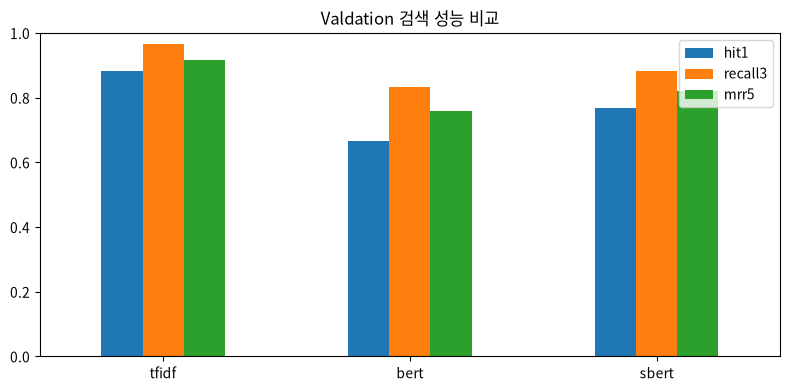

In [ ]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)
    # TODO 8-1. sbert_query_cache에 query가 있으면 캐시를, 없으면 sbert_model.encode()를 사용하세요.
    if query in sbert_query_cache:
        query_vec = sbert_query_cache[query]
    else:
        query_vec = sbert_model.encode([query], normalize_embeddings=True)[0]

    # TODO 8-2. 질문 벡터와 sbert_doc_vectors의 코사인 유사도를 계산하고 top_k_results()로 검색 결과를 반환하세요.
    scores = cosine_scores(query_vec, sbert_doc_vectors)

    return top_k_results(scores, corpus_df, k)
    # raise NotImplementedError('CP-08 SBERT 검색을 구현하세요.')

# TODO 8-3. evaluate_search(search_sbert, valid_df)로 SBERT Validation을 평가하고
#           결과를 sbert_summary, sbert_detail이라는 이름으로 받으세요.
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)
print('sbert_summary', sbert_summary)

# TODO 8-4. tfidf_summary, bert_summary, sbert_summary를 comparison_df로 만드세요.
#             행: tfidf, bert, sbert / 열: hit1, recall3, mrr5
comparison_df = pd.DataFrame([tfidf_summary, bert_summary, sbert_summary], index=['tfidf', 'bert', 'sbert'])[['hit1', 'recall3', 'mrr5']]

# TODO 8-5. comparison_df를 cp08_validation_comparison.csv로 저장하고 막대그래프를 그리세요.
comparison_df.to_csv(TABLES / 'cp08_validation_comparison.csv', encoding='utf-8-sig')

ax = comparison_df.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_ylim(0, 1)
ax.set_title('Valdation 검색 성능 비교')
plt.tight_layout()
plt.savefig(FIGURES / 'cp08_validation_comparison.png', dpi=150)
plt.show()
# raise NotImplementedError('CP-08 세 검색 방식의 성능을 비교하세요.')


**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [25]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


CP-08 통과: 세 검색 방식의 Validation 평가 완료


**[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이:   
TF-IDF: {'hit1': 0.88, 'recall3': 0.97, 'mrr5': 0.92}
BERT: {'hit1': 0.67, 'recall3': 0.83, 'mrr5': 0.76}
SBERT: {'hit1': 0.77, 'recall3': 0.88, 'mrr5': 0.82}  
TF-IDF가 HIT@1, Recall@3, MRR@5 의 수치가 다른 검색기보다 높게 나왔습니다. 그다음은 SBERT, BERT 순입니다.

- 예상과 다른 결과가 있다면 가능 원인: SBERT가 문맥까지 고려하기때문에 높게 나올거라고 예상했습니다. 그런데 TF-IDF가 높게 나온것은 TF-IDF가 단순히 단어가 포함된 것으로 검색하므로 데이터 구성이 문서에 질문의 단어가 겹치는경우가 많았기 때문이라고 생각합니다.

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [26]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
# TODO 9-1. tfidf_detail, bert_detail, sbert_detail을 query_id로 병합하세요.
#             각 모델의 hit1/recall3/rank에는 모델 이름 접두사를 붙이세요.
for name, detail in [('tfidf', tfidf_detail), ('bert', bert_detail), ('sbert', sbert_detail)]:
    part = detail[['query_id', 'hit1', 'recall3', 'rank']].rename(columns={
        'hit1': f'{name}_hit1',
        'recall3': f'{name}_recall3',
        'rank': f'{name}_rank',
    })
    error_df = error_df.merge(part, on='query_id')

# TODO 9-2. num_top1_failures = 3 - 세 모델의 hit1 합계를 계산하세요.
error_df['num_top1_failures'] = 3 - error_df[['tfidf_hit1', 'bert_hit1', 'sbert_hit1']].sum(axis=1)

print('error_df')
print('--')
print(error_df.iloc[0])
print('--')

# TODO 9-3. 실패가 많은 질문 상위 5개를 error_cases로 추출해 표로 출력하세요.
error_cases = error_df.sort_values('num_top1_failures', ascending=False).head(5)
display(error_cases)

# TODO 9-4. 질문 하나에 대한 세 검색기의 Top-3 doc_id·유사도를 출력하세요.

question = error_df.iloc[0]['question']

print('question:', question)
print('')

tfidf_result = pd.DataFrame(search_tfidf(question, 3))
print('tfidf top3')
print(tfidf_result[['doc_id', 'score']])

bert_result = pd.DataFrame(search_bert(question, 3))
print('')
print('bert top3')
print(bert_result[['doc_id', 'score']])

sbert_result = pd.DataFrame(search_sbert(question, 3))
print('')
print('sbert top3')
print(sbert_result[['doc_id', 'score']])

# TODO 9-5. error_cases를 TABLES/'cp09_error_cases.csv'에 저장하세요.
# [힌트] CP-01의 valid_overlap[['query_id', 'overlap']]을 query_id로 병합해 두면
#        실패한 질문의 겹침 비율을 함께 볼 수 있습니다.
# raise NotImplementedError('CP-09 검색 실패 사례를 비교하세요.')


error_df
--
query_id                                 QV001
question             종교 개혁 전 영국에서 인기를 끌었던 헌신은?
relevant_doc_id                           D015
tfidf_hit1                                 1.0
tfidf_recall3                              1.0
tfidf_rank                                 1.0
bert_hit1                                  1.0
bert_recall3                               1.0
bert_rank                                  1.0
sbert_hit1                                 0.0
sbert_recall3                              1.0
sbert_rank                                 2.0
num_top1_failures                          1.0
Name: 0, dtype: object
--


,query_id,question,relevant_doc_id,tfidf_hit1,tfidf_recall3,tfidf_rank,bert_hit1,bert_recall3,bert_rank,sbert_hit1,sbert_recall3,sbert_rank,num_top1_failures
19,QV020,소넨이 상을 받았던 해는?,D138,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,NaN,3.0
46,QV047,자바 API를 개발한 회사는 어디인가?,D048,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,4.0,3.0
13,QV014,이순몽 장군의 자택이 설립된 시기는?,D170,1.0,1.0,1.0,0.0,0.0,NaN,0.0,0.0,NaN,2.0
18,QV019,오브스테트릭스의 뜻에 대해 연구한 사람은?,D128,1.0,1.0,1.0,0.0,0.0,NaN,0.0,0.0,NaN,2.0
23,QV024,이윤필의 아버지는 누구인가?,D134,0.0,1.0,2.0,0.0,1.0,2.0,1.0,1.0,1.0,2.0


question: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?

tfidf top3
  doc_id     score
0   D015  0.142069
1   D078  0.069731
2   D175  0.065917

bert top3
  doc_id     score
0   D015  0.693191
1   D124  0.645154
2   D068  0.640854

sbert top3
  doc_id     score
0   D040  0.344475
1   D015  0.332107
2   D041  0.327652


In [27]:
# 1) error_df에 overlap 열 붙이기
check = error_df.merge(valid_overlap[['query_id', 'overlap']], on='query_id')

# 2) 실패한 질문의 겹침 비율 vs 전체 평균
print('전체 평균 overlap:', round(check['overlap'].mean(), 3))
print('대표 실패 5개 평균 overlap:', round(check[check['query_id'].isin(error_cases['query_id'])]['overlap'].mean(), 3))
print(check.groupby('num_top1_failures')['overlap'].mean().round(3))

# 3) 겹침 낮음/높음 그룹별로 각 검색기의 hit1
median = check['overlap'].median()
check['group'] = np.where(check['overlap'] < median, 'low', 'high')
print(check.groupby('group')[['tfidf_hit1', 'bert_hit1', 'sbert_hit1']].mean().round(3))

전체 평균 overlap: 0.474
대표 실패 5개 평균 overlap: 0.425
num_top1_failures
0.0    0.548
1.0    0.386
2.0    0.365
3.0    0.381
Name: overlap, dtype: float64
       tfidf_hit1  bert_hit1  sbert_hit1
group                                   
high        0.968      0.806       0.839
low         0.793      0.517       0.690


**[기록] 결과 해석 — CP-09**

- 대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등):   

 '자바 API를 개발한 회사는 어디인가?' 라는 질문에  
bert와 tf-idf가 각 0.660, 0.108로 찾은 'D013 마이데이터 기반 맞춤형 동네 맛집 정보 서비스 '페이노트' 앱 출시' 내용은 bert는 '개발한', 'API'같은 라는 특정 단어가 겹치고 맥락도 비슷해서 잘못 조회된것같습니다.  
 sbert'에서도 정답을 검색하지 못했는데, 답안인 '美법원 "SW, 특허 넘어 저작권도 인정"'는 내용이 '자바 API 개발한 회사' 보다는 '저작권' 쪽으로 문서벡터 방향이 치우쳐있었기때문이고 오답인 '1인 제조업을 한다'라는 문서를 찾았는데 점수는 0.384로 낮기도 하지만 내용에 '제조업' ,'생산'이라는 단어가 유사한 의미라서 *의미 혼동*으로 검색이 된것같습니다.  
  
'소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?' 질문에 bert가 0.689로 'D039 양 (남조)' 문서를 찾았는데 2위인 0.686이 정답이었습니다. '왕', '황제' 같은 문서 내용과 질문의 '여왕' '대륙'같은 단어의 벡터가 비슷한 방향이었을것입니다. 정답을 맞춘 sbert와 다른 결과가 나온 이유는 sbert는 앞뒤 문장끼리의 코사인 유사도를 비교하므로 문서를 더 잘 구별했고 bert는 그렇지 않고 양방향으로 문맥을 봤어도 MLM(빈칸 맞추기)로 학습했기 때문에 정확도가 떨어진 것같습니다.

'싸움에 대비한 체육을 다룬 교육의 명칭'을 묻는 질문에 bert로 서양 근세 교육과 관련된 내용을 검색했고 문서 내용이 '인문주의 운동', '교육 활동' 등을 설명하다보니 질문과 유사한 맥락으로 조회된것같습니다. 비슷한것을 찾았지만 '교육은 … 전투에 도움이 되는 실전 체육이 주된 내용이었으며, 이를 아고게라고 한다.' 라는 부분이 문서의 작은 비중을 차지하고있어 *회석* 되었기때문에 '체육을 다룬 명칭'이라는 문장의 답을 찾지 못했습니다. 그러다보니 sbert는 질문의 '싸움'과 벡터방향이 비슷한 '베트남전' 관련 문서를 찾게되었습니다.
  
'서울시가 룸셰어링 정책을 처음으로 시행한 행정구역은?'질문에는 bert가 0.658로 '네이버 횡포 막기 상생협의체 가동' 문서를 조회했는데 질문의 '서울', '처음', '정부정책' 이라는 맥락과 문서의 '서울', '처음', '협의체 가동'의 맥락이 비슷해서 검색했고,  
'룸셰어링'을 '룸','##셰','##어링'으로 토큰을 쪼개어 검색하고 문서에는 250개의 토큰중 3개로 적은 비중이라 핵심단어가 *희석*된것으로 보입니다.
  
'소넨이 상을 받았던 해를'묻는 질문에 tf-idf로는 상을 받은 대학생 문서를 조회했는데 '상' '받았다' 에 단어 검색을 하다보니 질문의 요지와 다른 검색이 되었습니다. sbert로는 베토벤 피아노 삼중주 내용이 검색됬는데 점수가 높은 점수가 0.384 인것으로 보아 제대로 검색하지 못한것같습니다. 학습데이터에서 이 질문이 없어서 일수도 있고, '소넨'이라는 단어게 '소', '##넨'이라는 의미없는 단어로 쪼개지면서 '상을 받았던 해'를 핵심단어로 찾다보니 sbert는 '1811년에 완성한' 베토벤 문서를, bert는 '신인상을 수상한' 다른 기사를 검색하게되었습니다. (*표면 단어 불일치*)



- 실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?:   
실패한 질문의 겹침 비율은 전체 평균보다 작았습니다. 겹침이 높은 질문도, 낮은 질문도 모두 tf-idf 검색기가 더 잘 찾았습니다. 단, sbert가 겹침이 줄어들때 덜  성능이 가잘 덜 떨어지는것을 확인했습니다.(겹침에 덜 흔들림)


**겹침 그룹별 hit1** (overlap 중앙값 0.462 기준)

| group | tfidf_hit1 | bert_hit1 | sbert_hit1 |
|---|---|---|---|
| 겹침 높음 (31개) | 0.968 | 0.806 | 0.839 |
| 겹침 낮음 (29개) | 0.793 | 0.517 | 0.690 |
| 겹침이 낮아질때 겹침 하락 폭 | −0.175 | −0.289 | −0.149 |
| 겹침 가장 낮은 10개 | 0.7 | 0.6 | 0.8 |
  

- CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?:  
tf-idf/bert의 장단점이 확인되었습니다. 겸치는 단어가 문장에서 비중이 적고 나머지 단어가 질문을 구성한 단어와 비슷한 방향의 벡터로 구성되었다면 bert가 제 성능을 내지 못했습니다. 또 토크나이저가 고유명사를 토큰으로 쪼개면서 그 단어가 검색에 하나의 단어로 쓰이지 않는 문제가 있었습니다.  
tf-idf 는 예상대로 겹침 정도에 비례하여 검색 했습니다. 예상대로 겹침이 적어질수록 성능이 떨어지는 것이 보입니다. 겹침이 적어지면 bert가 더 좋은 성능을 보였습니다. 
  
  
- 어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?:  
tf-idf를 최종 검색기로 했을때, 겹침이 많으면 좋은 성능 적을때 나쁜 성능을 보입니다. 그리고 단어가 겹치고 내용은 다른 문장에 대해서도 틀린 답을 검색 할 수 있습니다.


**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [28]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
# TODO 9-6. 검색기를 사용할 실제 상황을 USE_CASE로 한 문장 작성하세요.
USE_CASE = '사내 자료를 검색하면 다양한 부서에서 작성한 모든 관련 문서를 보여주는 기능'

# TODO 9-7. PRIORITY_METRIC을 'hit1', 'recall3', 'mrr5' 중 하나로 지정하세요.
PRIORITY_METRIC = 'mrr5'

# TODO 9-8. comparison_df의 Validation 점수와 오류 사례를 고려하여
#             SELECTED_METHOD를 'tfidf', 'bert', 'sbert' 중 하나로 직접 선택하세요.
SELECTED_METHOD = 'tfidf'

# TODO 9-9. SELECTION_REASON에 실제 수치와 다른 방법의 장단점을 2~3문장으로 적으세요.
SELECTION_REASON = 'tfidf 가 단어 검색에 있어서는 mrr5이 0.9166666666666666 로 높았기때문입니다. 문맥 파악이 필요한 업무에서는 sbert가 나을거같습니다. 예를들면 회사 게시판에 올라오는 악플 감지기능 처럼 거친표현은 없지만 내용이 나쁜 경우.'

# raise NotImplementedError('CP-09 최종 검색 방식·판단 근거를 지정하세요.')

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)


선정 모델: tfidf | 우선 지표: mrr5


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [31]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""

    
    # TODO 10-1. method가 'tfidf'라면 search_tfidf(), 'bert'라면 search_bert(),
    #              'sbert'라면 search_sbert()를 호출하도록 작성하세요.
    if method == 'tfidf':
        results = search_tfidf(query, k)
    elif method == 'bert':
        results = search_bert(query, k)
    else:
        results = search_sbert(query, k)

    return results
    # TODO 10-2. 세 방법 모두 동일한 rank/doc_id/score/text 구조로 반환하세요.
    # raise NotImplementedError('CP-10 최종 search_docs()를 구현하세요.')

# TODO 10-3. 본인이 만든 새로운 질문 한 개로 search_docs() Top-3를 확인하세요.


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [40]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)
test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20
# TODO 10-4. SELECTED_METHOD를 바꾸지 않고 search_docs()로 Test 질문 20개를 평가하고
#            결과를 test_summary, test_detail이라는 이름으로 받으세요.
test_summary, test_detail = evaluate_search(search_docs, test_df)

# TODO 10-5. comparison_df의 선택 모델 Validation 점수와 Test 점수를 final_compare라는 DataFrame으로
#            정리하세요. 행은 Validation, Test 두 개입니다.
final_compare = pd.DataFrame(
    [comparison_df.loc[SELECTED_METHOD].to_dict(), test_summary],
    index=['Validation', 'Test']
)[['hit1', 'recall3', 'mrr5']]
print(final_compare)

# TODO 10-6. final_compare는 TABLES / 'cp10_validation_test_comparison.csv'로,
#            test_detail은 TABLES / 'cp10_test_query_results.csv'로 저장하세요.
final_compare.to_csv(TABLES / 'cp10_validation_test_comparison.csv', encoding='utf-8-sig')
test_detail.to_csv(TABLES / 'cp10_test_query_results.csv', encoding='utf-8-sig')

# TODO 10-7. 선택 방법, 우선 지표, Validation·Test 점수를 REPORTS / 'cp10_final_report.json'에 저장하세요.
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation_metrics': final_compare.loc['Validation'].to_dict(),
    'test_metrics': test_summary,
}
(REPORTS / 'cp10_final_report.json').write_text(
    json.dumps(final_report, ensure_ascii=False, indent=2), encoding='utf-8')

# [주의] 검증 셀이 위 변수 이름과 파일 이름을 그대로 확인합니다.
#raise NotImplementedError('CP-10 최종 Test 평가 및 CSV/JSON 저장을 완성하세요.')


                hit1   recall3      mrr5
Validation  0.883333  0.966667  0.916667
Test        0.800000  0.800000  0.812500


271

**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [41]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- 최종 선택 모델의 Validation 및 Test 지표 차이:   
Validation에서는 잘 검색이 되었으나 Test에서는 그보다 못한 결과를 보여주었습니다. recall3, hit1과 mrr5도 0.96, 0.88, 0.91 로 Validation에서는 상당히 높지만 Test에서는 0.8, 0.8, 0.815로 많이 낮아졌습니다
    
- 검색에 실패한 Test 질문의 특징과 예상 원인:   
'거제조선소의 기업설명회에서 발표한 인물의 이름은?' 질문에 '오늘 하나SK·외환카드 합병 의결...통합사명은 '하나카드' 유력' 을 검색했는데 '기업설명회', '발표' 단어가 겸치고 정답에는 질문에있는 '거제조선소', '기업설명회' 이런 단어게 내용에 없어서 찾지 못한것으로 보입니다. 내용은 맞는데 단어가 없어서 못찾은것같습니다.

'척수근육 위축증을 가진 인물이 참여한 팀의 명칭은?' 짐룬에 '정부, AIIB 참여 결정...창립멤버 실익 챙긴다 '를 검색했습니다. 정답에 '김씨는 척수근육위축증을 앓고 있는데' 문장이 있어서 찾을수도 있었을것같은데, '참여'라는 단어가 자주 나와서 미세하게 점수차 0.0021로 틀린 것을 검색한것같습니다.  

'웃는 감정을 그대로 표현한다는 뉘앙스를 갖는 ㅋ의 용법은?'질문에 '강현 초상'을 검색했는데 질문의 핵심단어 'ㅋ'가 정답문서에 없어서 '그대로', '표현' 이런 단어로 검색하다보니 완전히 엉뚱한 내용을 검색했고 점수또한 겹침도 0.118로 낮았습니다. 

'투자에 적극적인 인물의 이름은?' 질문에 '오늘 하나SK·외환카드 합병 의결...통합사명은 '하나카드' 유력'를 검색했습니다. '이름'이 내용에 반복적으로 나와서 검색이 된 것같습니다. 반면에 정답에는 '이름이 **다' 라는 식으로 적혀있지 않다보니 점수가 0.032로 찾지못했습니다.  
  

- 이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유:  
문서 200개, Test 질문이 20개로 데이터 양이 적어서 실제로 같능 성능올 보일지 확실하지 않습니다. 질문의 단어가 문서에 들어가는 경우가 많아서 tf-idf가 유리한 결과로 나왔을수 있습니다. 실제 사람이 하는 질문에는 대답의 단어가 들어가있지 않은 경우가 많습니다.


### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.
